# 05 · Early-Exit GNN

The model itself: a weight-tied SAS-GNN backbone with an exit head after every
layer, and a learned Gumbel-softmax halting policy that decides per patient how
deep to propagate.

Three claims to test, in order:

1. **The exit distribution is non-trivial.** If every patient exits at layer 1
   (or every patient runs to full depth), the halting policy has learned
   nothing and this is a fixed-depth GNN with extra steps.
2. **Accuracy at reduced average depth matches full depth.** The efficiency claim.
3. **The mixture is calibrated.** Halting early on a patient the model is
   overconfident about is worse than never halting — miscalibration and early
   exit compound.

HANDOVER §6.2 records claim 1 failing on synthetic data: the policy collapsed to
all-shallow, or under a strong halt penalty to all-deep, because depth bought no
accuracy. Whether it fails here was largely decided in notebook 03.

In [1]:
exec(open("/kaggle/working/clinical-eegnn/notebooks/src/_bootstrap.py").read())
from src import mimic_iv, graph_build as gb
from src.data_prep import make_splits, impute_and_scale
from src.train import set_seed, get_device, train_model
from src.evaluate import evaluate_model, calibrate_on_val, reliability_curve
import torch, matplotlib.pyplot as plt

cfg = mimic_cfg()
set_seed(cfg["seed"])
X_raw, y, names, meta = mimic_iv.build_cohort(cfg, verbose=False)
train, val, test = make_splits(y, cfg["seed"])
X = impute_and_scale(X_raw, train)
data = gb.build_graph(X, y, (train, val, test), cfg, meta=meta,
                      cache_dir=CACHE).to(get_device())

print(gb.describe(data))
print("max_layers", cfg["model"]["max_layers"],
      "| ponder_cost", cfg["train"]["ponder_cost"],
      "| halt_penalty", cfg["train"]["high_risk_halt_penalty"])
print("has criticalness:", hasattr(data, "criticalness"))

nodes=17663 edges=426496 avg_degree=24.15 features=542 prevalence={'train': 0.10776635259389877, 'val': 0.10784036666154861, 'test': 0.10784036666154861}
max_layers 10 | ponder_cost 0.01 | halt_penalty 0.05
has criticalness: True


## Train

The Gumbel temperature anneals from `gumbel_tau_start` to `gumbel_tau_end`:
early on the halting decision is soft and gradients reach every exit head; by
the end it is nearly discrete, matching inference.

  epoch    0  loss 0.3316  val_auroc 0.7963  avg_depth 1.99  tau 5.00


  epoch   25  loss 0.1565  val_auroc 0.8792  avg_depth 2.43  tau 4.12


  epoch   50  loss 0.1122  val_auroc 0.8747  avg_depth 2.94  tau 3.40


  early stop at epoch 61 (best 10)

trained in 8.4s | best val AUROC 0.8806 at epoch 10


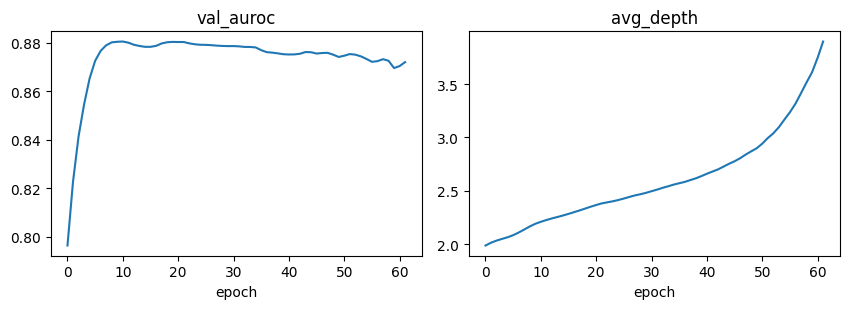

In [2]:
set_seed(cfg["seed"])
t0 = time.time()
model, history, best = train_model(data, cfg, use_exits=True, verbose=True,
                                   log_every=25)
print(f"\ntrained in {time.time()-t0:.1f}s | best val AUROC "
      f"{best['auroc']:.4f} at epoch {best['epoch']}")

h = pd.DataFrame(history)
cols = [c for c in ["loss", "val_auroc", "avg_depth"] if c in h.columns]
fig, ax = plt.subplots(1, len(cols), figsize=(4.3 * len(cols), 3.2))
for a, c in zip(np.atleast_1d(ax), cols):
    a.plot(h["epoch"], h[c]); a.set_title(c); a.set_xlabel("epoch")
plt.tight_layout(); plt.show()

## Calibrate, then evaluate

Temperature is fit on the **validation** split only. Fitting it on test would
report a calibration number no deployment could reproduce.

In [3]:
T = calibrate_on_val(model, data)
T_per_exit = calibrate_on_val(model, data, per_exit=True)
print("global temperature:", round(float(T), 4))

res_raw = evaluate_model(model, data, cfg, split="test")
res = evaluate_model(model, data, cfg, split="test", temperature=T,
                     exit_temperatures=T_per_exit)

print("\npredictive :", {k: round(v, 4) for k, v in res["predictive"].items()
                         if isinstance(v, float)})
print("calib raw  :", {k: round(v, 4) for k, v in res_raw["calibration"].items()})
print("calib scaled:", {k: round(v, 4) for k, v in res["calibration"].items()})
print("efficiency :", {k: round(v, 4) if isinstance(v, float) else v
                       for k, v in res["efficiency"].items()})

global temperature: 0.3767



predictive : {'auroc': 0.8816, 'auprc': 0.5395, 'f1': 0.3696, 'sensitivity': 0.9003, 'specificity': 0.6409, 'ppv': 0.2325, 'threshold': 0.2592}
calib raw  : {'ece': 0.2237, 'brier': 0.1316}
calib scaled: {'ece': 0.1519, 'brier': 0.1123}
efficiency : {'avg_exit_depth': 6.2992, 'max_depth': 10, 'depth_saving_pct': 37.0082, 'flops_per_patient': 71071.915, 'latency_s_per_patient': 0.0}


## Claim 1 — is the exit distribution non-trivial?

       n   share
1      1  0.0003
2    266  0.0753
3      6  0.0017
4   1186  0.3357
5    294  0.0832
6    348  0.0985
7    154  0.0436
8    191  0.0541
9     74  0.0209
10  1013  0.2867

mean exit depth 6.30 of 10  (37.0% depth saved)
VERDICT: non-trivial exit distribution


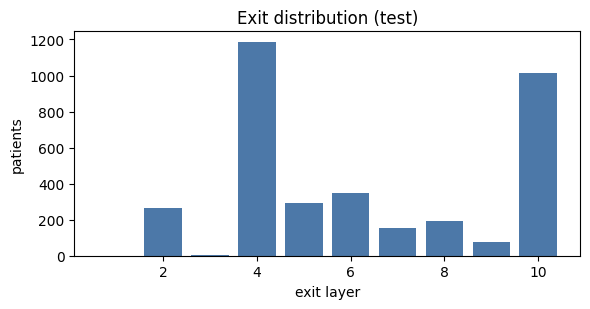

In [4]:
dist = pd.Series(res["exit_distribution"]).sort_index()
share = dist / dist.sum()
print(pd.DataFrame({"n": dist, "share": share.round(4)}).to_string())

collapsed = share.max() > 0.95
print(f"\nmean exit depth {res['efficiency']['avg_exit_depth']:.2f} "
      f"of {cfg['model']['max_layers']}  "
      f"({res['efficiency']['depth_saving_pct']:.1f}% depth saved)")
print("VERDICT:", "COLLAPSED -- the policy is effectively fixed-depth"
      if collapsed else "non-trivial exit distribution")

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.bar(dist.index, dist.values, color="#4C78A8")
ax.set_xlabel("exit layer"); ax.set_ylabel("patients")
ax.set_title("Exit distribution (test)")
plt.tight_layout(); plt.show()

## Claim 2 — per-exit quality

Whether each exit is individually trustworthy, or whether shallow exits only
work because the mixture rescues them.

 layer  n_exiting  auroc  auprc    ece
     1          1 0.8823 0.5363 0.1529
     2        266 0.8810 0.5310 0.1518
     3          6 0.8797 0.5354 0.1597
     4       1186 0.8768 0.5254 0.1513
     5        294 0.8813 0.5397 0.1518
     6        348 0.8810 0.5396 0.1385
     7        154 0.8840 0.5436 0.1439
     8        191 0.8817 0.5367 0.1561
     9         74 0.8812 0.5436 0.1697
    10       1013 0.8804 0.5428 0.1696


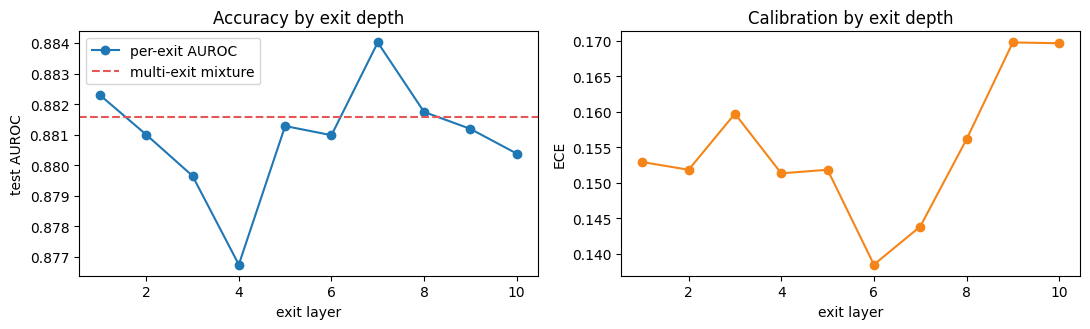

In [5]:
pe = pd.DataFrame(res["per_exit"])
print(pe[["layer", "n_exiting", "auroc", "auprc", "ece"]].round(4).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(pe["layer"], pe["auroc"], "o-", label="per-exit AUROC")
ax[0].axhline(res["predictive"]["auroc"], ls="--", c="#E45756", label="multi-exit mixture")
ax[0].set_xlabel("exit layer"); ax[0].set_ylabel("test AUROC"); ax[0].legend()
ax[0].set_title("Accuracy by exit depth")
ax[1].plot(pe["layer"], pe["ece"], "o-", color="#F58518")
ax[1].set_xlabel("exit layer"); ax[1].set_ylabel("ECE")
ax[1].set_title("Calibration by exit depth")
plt.tight_layout(); plt.show()

If per-exit AUROC is already flat by layer 1–2, depth is not buying accuracy and
the efficiency result is trivially available to any shallow fixed-depth model —
a much weaker claim than the project set out to make. A rising curve that
plateaus is the shape that makes adaptive depth worthwhile.

## Claim 3 — calibration

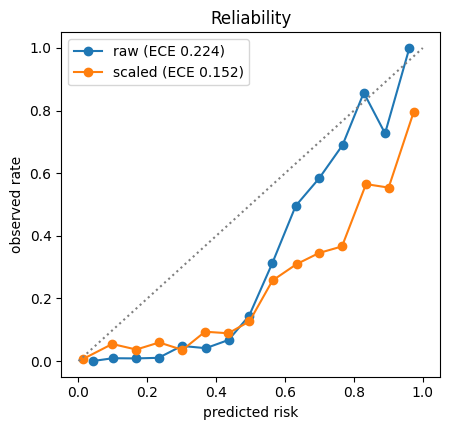

In [6]:
yt = data.y.cpu().numpy(); m = data.test_mask.cpu().numpy()
with torch.no_grad():
    out = model(data.x, data.edge_index, data.edge_weight, tau=0.5, hard=True)
p_raw = torch.softmax(out["final_logits"], -1)[:, 1].cpu().numpy()
p_cal = torch.softmax(out["final_logits"] / T, -1)[:, 1].cpu().numpy()

fig, ax = plt.subplots(figsize=(4.6, 4.4))
for p, lab in [(p_raw, f"raw (ECE {res_raw['calibration']['ece']:.3f})"),
               (p_cal, f"scaled (ECE {res['calibration']['ece']:.3f})")]:
    conf, acc, _cnt = reliability_curve(yt[m], p[m], cfg["eval"]["n_bins_ece"])
    ax.plot(conf, acc, "o-", label=lab)
ax.plot([0, 1], [0, 1], ls=":", c="grey")
ax.set_xlabel("predicted risk"); ax.set_ylabel("observed rate")
ax.set_title("Reliability"); ax.legend()
plt.tight_layout(); plt.show()

## Safety — do the sick get more depth?

Using the corrected metric: the high-risk stratum is the **top decile of
`criticalness`**, a severity proxy fixed before any prediction is made. The
previous definition ("high risk" = died, measured at a threshold pinned to 90%
sensitivity) made the miss rate identically `1 - 0.90` for every model — it sat
at a constant 0.104 across an entire sweep and carried no information
(HANDOVER §6.1).

In [7]:
safety = res["safety"]
for k, v in safety.items():
    print(f"  {k:28s} {round(v, 4) if isinstance(v, float) else v}")

print("\nSAFETY ORDERING:",
      "OK — high-risk patients propagate deeper" if safety["safety_ordering_ok"]
      else "INVERTED — the sick are being cut short, see HANDOVER §6.3")

  stratum                      top 10% of severity
  high_risk_n                  354
  high_risk_prevalence         0.3672
  high_risk_miss_rate          0.0154
  low_risk_miss_rate           0.1434
  high_risk_ece                0.3008
  low_risk_ece                 0.1363
  high_risk_mean_depth         6.0141
  low_risk_mean_depth          6.3309
  depth_gap                    -0.3168
  safety_ordering_ok           False
  high_risk_early_exit_rate    0.4435
  low_risk_early_exit_rate     0.502

SAFETY ORDERING: INVERTED — the sick are being cut short, see HANDOVER §6.3


An inverted ordering is the failure mode flagged in HANDOVER §6.3: `ponder_cost`
and `high_risk_halt_penalty` both act on the *global* mean depth rather than
separating the low- and high-risk cohorts, so the safety term behaves as a depth
lever rather than a selective one. Notebook 06 sweeps that trade-off.

In [8]:
torch.save({"state_dict": model.state_dict(), "cfg": cfg,
            "temperature": float(T),
            "exit_temperatures": [float(t) for t in np.atleast_1d(T_per_exit)]},
           f"{CACHE}/eegnn_model.pt")
json.dump({"predictive": res["predictive"], "calibration": res["calibration"],
           "calibration_raw": res_raw["calibration"], "efficiency": res["efficiency"],
           "safety": res["safety"], "per_exit": res["per_exit"],
           "exit_distribution": res["exit_distribution"]},
          open(f"{CACHE}/eegnn_results.json", "w"), indent=2, default=float)
print("wrote eegnn_model.pt and eegnn_results.json")

wrote eegnn_model.pt and eegnn_results.json


**Next:** `06_efficiency_safety_sweep` — the accuracy/compute trade-off curve
and whether the safety ordering survives across operating points.